# Issue #376 — corrected-chronology fixed N6 expert

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parents[2]
OUT=ROOT/'results/n6_chronology_sync'

In [2]:
performance=pd.read_csv(OUT/'performance.csv')
risk=pd.read_csv(OUT/'risk_diagnostics.csv')
bootstrap=pd.read_csv(OUT/'bootstrap_lift.csv')
coverage=pd.read_csv(OUT/'coverage_ledger.csv')
parity=pd.read_csv(OUT/'parity_summary.csv')
issue_parity=pd.read_parquet(OUT/'legacy_issue_parity.parquet')
performance

,scope,arm,issues,stake_cny,gross_cny,pnl_cny,ending_capital_cny,capital_return,stake_roi,hit_rate
0,2022,R0,51,52224.0,29811.800439,-22412.199561,77587.800439,-0.224122,-0.429155,0.235294
1,2022,R3,51,52224.0,23678.579949,-28545.420051,71454.579949,-0.285454,-0.546596,0.156863
2,2023,R0,47,48128.0,28402.876403,-19725.123597,80274.876403,-0.197251,-0.409847,0.234043
3,2023,R3,47,48128.0,45429.109821,-2698.890179,97301.109821,-0.026989,-0.056077,0.170213
4,2024,R0,54,55296.0,63922.231530,8626.231530,108626.231530,0.086262,0.156001,0.425926
5,2024,R3,54,55296.0,74240.320588,18944.320588,118944.320588,0.189443,0.342598,0.370370
6,ALL,R0,152,155648.0,122136.908371,-33511.091629,66488.908371,-0.335111,-0.215300,0.302632
7,ALL,R3,152,155648.0,143348.010358,-12299.989642,87700.010358,-0.123000,-0.079024,0.236842


In [3]:
risk

,scope,arm,max_drawdown_fraction,longest_losing_run,open_underwater_issues,largest_payout_share,payout_hhi
0,2022,R0,0.244454,12,51,0.169757,0.107363
1,2022,R3,0.288668,17,51,0.213728,0.145928
2,2023,R0,0.269051,12,47,0.188630,0.129723
3,2023,R3,0.207599,19,39,0.543346,0.338849
4,2024,R0,0.065674,6,13,0.129696,0.063784
5,2024,R3,0.156484,9,1,0.236449,0.110096
6,ALL,R0,0.493173,12,152,0.067878,0.030883
7,ALL,R3,0.468927,19,152,0.172194,0.067544


In [4]:
bootstrap

,scope,issues,matched_lift_cny,ex_largest_lift_cny,bootstrap_p025_cny,bootstrap_median_cny,bootstrap_p975_cny
0,2022,51,-6133.220490,-1334.565472,-22288.045569,-5839.434793,10563.400847
1,2023,47,17026.233418,-7657.473226,-25531.821435,14626.385126,82550.986694
2,2024,54,10318.089058,-7235.938222,-35023.065325,7527.978887,66355.986915
3,ALL,152,21211.101987,-3472.604657,-45894.803018,20082.400497,110604.070925


In [5]:
coverage_summary=(coverage.groupby(['issue_year','settlement_complete'],dropna=False).size().rename('issues').reset_index())
coverage_summary

,issue_year,settlement_complete,issues
0,2022,False,7
1,2022,True,51
2,2023,False,8
3,2023,True,47
4,2024,False,5
5,2024,True,54


In [6]:
parity

,layer,old_rows,new_rows,common_rows,exact_rows,year_exact_rows,fixture_exact_rows,support_exact_rows,settlement_exact_rows,score_exact_rows
0,issue_arm,318,304,304,10,288.0,206.0,12.0,277.0,NaN
1,ticket_design,362,344,344,344,NaN,NaN,NaN,NaN,NaN
2,action,51917,48658,48658,8630,45954.0,NaN,22489.0,NaN,14442.0


In [7]:
changed=issue_parity[(issue_parity['_merge']=='both') & (~issue_parity['exact_issue_arm'])]
changed[['issue','arm','old_issue_year','new_issue_year','exact_selected_match_ids','exact_support_json','exact_pnl_cny']].head(20)

,issue,arm,old_issue_year,new_issue_year,exact_selected_match_ids,exact_support_json,exact_pnl_cny
14,22013,R0,2022,2022.0,True,False,True
15,22013,R3,2022,2022.0,True,False,True
16,22015,R0,2022,2022.0,True,False,True
17,22015,R3,2022,2022.0,True,False,True
18,22021,R0,2022,2022.0,False,False,True
19,22021,R3,2022,2022.0,False,False,True
20,22023,R0,2022,2022.0,False,False,True
21,22023,R3,2022,2022.0,False,False,True
22,22033,R0,2022,2022.0,True,False,True
23,22033,R3,2022,2022.0,True,False,True


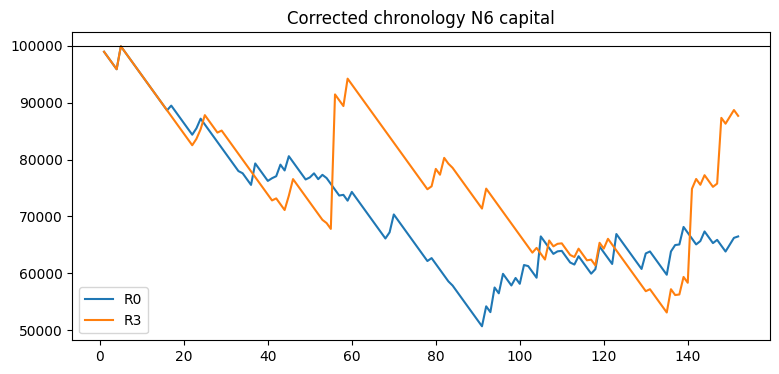

In [8]:
paths=pd.read_csv(OUT/'capital_paths.csv')
fig,ax=plt.subplots(figsize=(9,4))
for arm,g in paths[paths.scope.eq('ALL')].groupby('arm'):
    ax.plot(g.issue_order,g.capital_cny,label=arm)
ax.axhline(100000,color='black',lw=.8); ax.legend(); ax.set_title('Corrected chronology N6 capital'); plt.show()